# **Assignment 3B**

### This notebook tests the Formula 1 race simulator, including normal and special race simulations, tire degradation, pit-stop behavior, input validation, and optimal tire strategy selection.

In [11]:
import part2 
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt


In [12]:
import importlib
import part2

importlib.reload(part2)

simulator = part2.RaceSimulator()

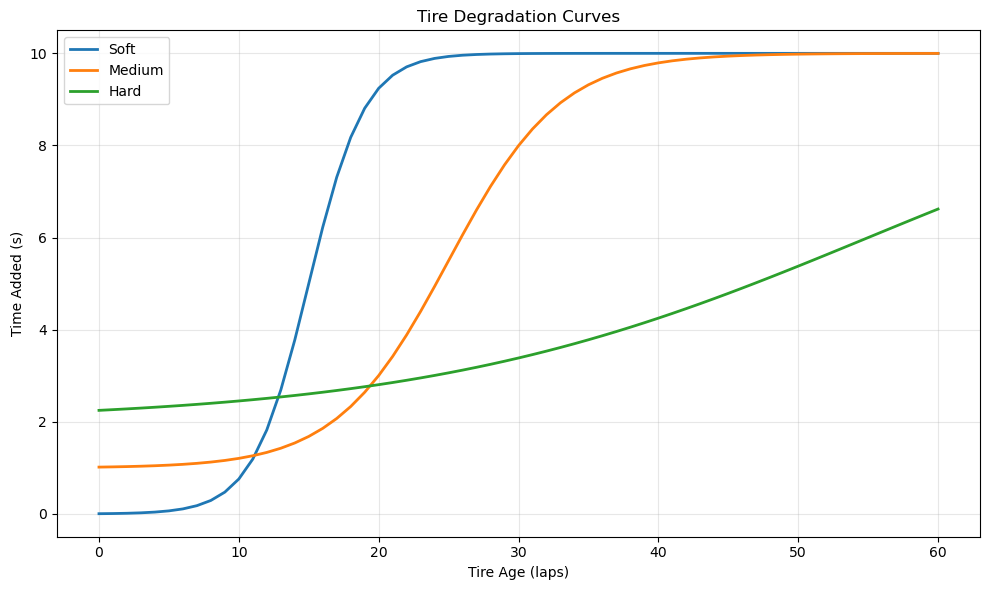

In [3]:
part2.plot_tires(simulator)

# **Test Cases**

## Normal Test Case

In [9]:

# NORMAL TEST CASE

# Input
stint_lengths = [20, 25, 15]
tire_types = ["Soft", "Medium", "Hard"]

# Expected behaviour:
# - Three stints
# - 60 total laps
# - At least two different tire compounds
# - 60 rows and 3 columns in the race DataFrame
# - 50 seconds added for pit stops

simulator = part2.RaceSimulator()

total_time = simulator.simulate(stint_lengths, tire_types)
normal_race_df = simulator.race_df
race_df = normal_race_df
assert np.isclose(total_time, race_df["tire_time_added"].sum() + 50)

# Actual results
print("Total additional race time:", round(total_time, 2))
print("DataFrame dimensions:", race_df.shape)
print("Tire compounds used:")
print("Total tire degradation:", round(race_df["tire_time_added"].sum(),2))
print(race_df["tire_type"].value_counts())

# Verify expected results
assert len(race_df) == 60
assert race_df.shape == (60, 3)
assert len(race_df["tire_type"].unique()) >= 2
assert round(total_time, 2) == 180.54
assert race_df["tire_type"].value_counts().to_dict() == {
    "Medium": 25,
    "Soft": 20,
    "Hard": 15
}

print("\nNormal test case passed!")


Total additional race time: 180.54
DataFrame dimensions: (60, 3)
Tire compounds used:
Total tire degradation: 130.54
tire_type
Medium    25
Soft      20
Hard      15
Name: count, dtype: int64

Normal test case passed!


In [5]:
# Display rows around the two pit stops

print("First pit stop:")
print(normal_race_df.iloc[18:22])

print("\nSecond pit stop:")
print(normal_race_df.iloc[43:47])

# Verify tire age resets at both pit stops
assert normal_race_df.iloc[20]["tire_age"] == 0
assert normal_race_df.iloc[45]["tire_age"] == 0

print("\nBoth pit-stop tire-age reset tests passed!")

First pit stop:
   tire_type  tire_age  tire_time_added
18      Soft        18         8.175745
19      Soft        19         8.807971
20    Medium         0         1.017341
21    Medium         1         1.022254

Second pit stop:
   tire_type  tire_age  tire_time_added
43    Medium        23         4.397866
44    Medium        24         4.940411
45      Hard         0         2.249151
46      Hard         1         2.264688

Both pit-stop tire-age reset tests passed!


## Special Test Case

In [14]:

# SPECIAL TEST CASE

# Input
stint_lengths = [20, 20, 20]
tire_types = ["Soft", "Medium", "Soft"]

# Expected behaviour:
# - Three equal-length stints
# - 60 total laps
# - Two different tire compounds
# - Valid simulation with 60 rows

simulator = part2.RaceSimulator()

total_time = simulator.simulate(stint_lengths, tire_types)
race_df = simulator.race_df

# Actual results
print("Stint lengths:", stint_lengths)
print("Tire compounds:", tire_types)
print("Total additional race time:", round(total_time, 2))
print("DataFrame dimensions:", race_df.shape)

# Verify expected results
assert sum(stint_lengths) == 60
assert len(set(tire_types)) == 2
assert race_df.shape == (60, 3)
assert list(race_df["tire_age"].iloc[[0, 20, 40]]) == [0, 0, 0]
assert round(total_time, 2) == 171.99

print("\nSpecial test case passed!")


Stint lengths: [20, 20, 20]
Tire compounds: ['Soft', 'Medium', 'Soft']
Total additional race time: 171.99
DataFrame dimensions: (60, 3)

Special test case passed!


## Error Test Case

In [7]:

# ERROR TEST CASES

simulator = part2.RaceSimulator()

error_tests = [
    {
        "description": "Incorrect number of stints",
        "stint_lengths": [30, 30],
        "tire_types": ["Soft", "Medium"],
        "expected_error": ValueError
    },
    {
        "description": "Incorrect total race distance",
        "stint_lengths": [20, 25, 20],
        "tire_types": ["Soft", "Medium", "Hard"],
        "expected_error": ValueError
    },
    {
        "description": "Invalid tire compound",
        "stint_lengths": [20, 25, 15],
        "tire_types": ["Soft", "Medium", "SuperSoft"],
        "expected_error": ValueError
    },
    {
        "description": "Only one tire compound",
        "stint_lengths": [20, 25, 15],
        "tire_types": ["Soft", "Soft", "Soft"],
        "expected_error": ValueError
    },
    {
        "description": "Zero-length stint",
        "stint_lengths": [20, 40, 0],
        "tire_types": ["Soft", "Medium", "Hard"],
        "expected_error": ValueError
    },
    {
        "description": "Non-integer stint length",
        "stint_lengths": [20, 25.5, 14.5],
        "tire_types": ["Soft", "Medium", "Hard"],
        "expected_error": TypeError
    }
]


passed_tests = 0

for test in error_tests:

    print("\nTest:", test["description"])

    try:
        simulator.simulate(
            test["stint_lengths"],
            test["tire_types"]
        )

    except test["expected_error"] as error:
        print("Expected error detected:", error)
        passed_tests += 1

    except Exception as error:
        raise AssertionError(
            f"Unexpected error in {test['description']}: "
            f"{type(error).__name__}: {error}"
        )

    else:
        raise AssertionError(
            f"Expected {test['expected_error'].__name__} "
            f"was not raised for {test['description']}."
        )

print(f"\n{passed_tests}/{len(error_tests)} error tests passed.")

assert passed_tests == len(error_tests)



Test: Incorrect number of stints
Expected error detected: A race must have exactly 3 stints.

Test: Incorrect total race distance
Expected error detected: Stint lengths must add up to 60 laps.

Test: Invalid tire compound
Expected error detected: Invalid tire type: SuperSoft

Test: Only one tire compound
Expected error detected: At least 2 different tire compounds are required.

Test: Zero-length stint
Expected error detected: Stint lengths must be positive.

Test: Non-integer stint length
Expected error detected: Stint lengths must be integers.

6/6 error tests passed.


In [13]:

# STRATEGY OPTIMIZATION TEST

simulator = part2.RaceSimulator()

best_strategy = part2.find_best_strategy(simulator)

best_stints = best_strategy[0]
best_tires = best_strategy[1]
best_time = best_strategy[2]

print("Best stint lengths:", best_stints)
print("Best tire compounds:", best_tires)
print("Minimum additional race time:", round(best_time, 2))

# Verify the winning strategy
assert len(best_stints) == 3
assert sum(best_stints) == 60
assert len(set(best_tires)) >= 2
assert simulator.race_df.shape == (60, 3)

# Verify the returned time matches the winning DataFrame
assert np.isclose(
    best_time,
    simulator.race_df["tire_time_added"].sum() + 50
)

print("\nStrategy optimization test passed!")


Best stint lengths: [15, 22, 23]
Best tire compounds: ['Soft', 'Medium', 'Medium']
Minimum additional race time: 134.27

Strategy optimization test passed!
